# 5 · Discover: what kinds of water are there?

**Syllabus:** Module 4 (clustering, similarity and distance measures, k-means,
agglomerative clustering).

The models so far were told the answer during training (supervised learning). Here
nobody tells the algorithm anything. We give it the temperature profiles measured by
6,144 Argo floats and ask: **which profiles look alike?**

Each profile is a list of temperatures at 14 depths (0–700 m). Two profiles are
"similar" when the **Euclidean distance** between those lists is small. That is
roughly the typical temperature difference, depth by depth.

Decisions made *before* looking at any result:

* **0–700 m only.** 1,000 m is missing in about a fifth of the casts (the floats
  that sampled shallower water), and dropping them would bias the sample towards
  deep, open water.
* **No standardisation.** Every column is a temperature in °C, so a degree counts the
  same at every depth. Standardising would blow up the tiny variations at 700 m to the
  same weight as the thermocline.
* **k is chosen by the silhouette score alone.** Only afterwards do we compare the
  clusters with the sea and the season the floats were in.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from scipy.cluster.hierarchy import linkage, dendrogram
import common as C

C.style()
casts = C.load_casts()
LEVELS = [d for d in C.DEPTHS if d <= 700]
X_all = casts[[f"obs_t{d}" for d in LEVELS]]
keep = X_all.notna().all(axis=1)
X = X_all[keep].to_numpy()
meta = casts[keep].copy()
SEASONS = {1: "Winter", 2: "Winter", 3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon", 6: "Monsoon", 7: "Monsoon",
           8: "Monsoon", 9: "Monsoon", 10: "Post-monsoon", 11: "Post-monsoon", 12: "Post-monsoon"}
meta["season"] = meta["day"].dt.month.map(SEASONS)
print(f"Complete 0–700 m profiles: {len(X):,} of {len(casts):,}")
C.record("cluster.profiles_used", len(X))

Complete 0–700 m profiles: 5,649 of 6,144


## 5.1 PCA: the main ways profiles differ

Principal component analysis finds the directions in which the profiles vary most.
Each component is itself a shape of profile.

Variance explained: [42.8 33.8 14.1  3.7  2. ] | first two together: 76.6


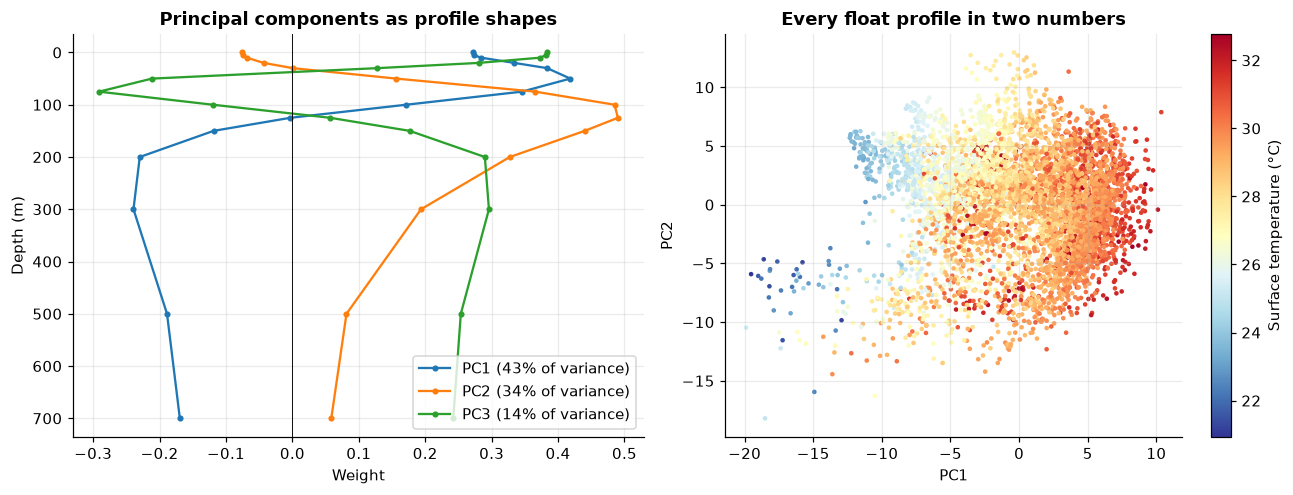

In [2]:
pca = PCA(n_components=5, random_state=C.SEED).fit(X)
Z = pca.transform(X)
ev = pca.explained_variance_ratio_ * 100
C.record("cluster.pca_explained_pct", ev.round(1))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for i in range(3):
    axes[0].plot(pca.components_[i], LEVELS, marker=".", label=f"PC{i + 1} ({ev[i]:.0f}% of variance)")
axes[0].axvline(0, color="k", lw=0.6); axes[0].invert_yaxis()
axes[0].set_xlabel("Weight"); axes[0].set_ylabel("Depth (m)"); axes[0].legend(); axes[0].set_title("Principal components as profile shapes")
sc = axes[1].scatter(Z[:, 0], Z[:, 1], c=meta["obs_t0"], s=4, cmap="RdYlBu_r")
plt.colorbar(sc, ax=axes[1], label="Surface temperature (°C)")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2"); axes[1].set_title("Every float profile in two numbers")
fig.tight_layout(); C.save(fig, "cluster_pca")
print("Variance explained:", np.round(ev, 1), "| first two together:", round(ev[:2].sum(), 1))

## 5.2 How many clusters? Elbow and silhouette

* **Elbow:** the within-cluster spread (inertia) always falls as k grows; look for the
  bend where adding clusters stops helping much.
* **Silhouette** (−1 to 1): for each profile, how much closer it is to its own cluster
  than to the next one. Higher is better, and the maximum picks k.

Chosen k: 3


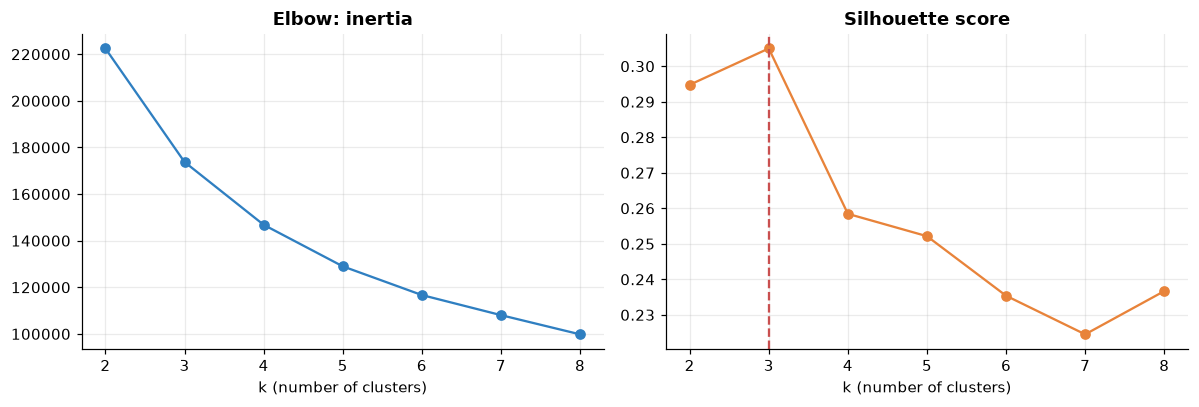

In [3]:
ks = range(2, 9)
scan = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=C.SEED).fit(X)
    scan.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_, sample_size=4000, random_state=C.SEED)})
scan = pd.DataFrame(scan)
K = int(scan.loc[scan["silhouette"].idxmax(), "k"])
C.record("cluster.k_scan", scan.round(4).to_dict("records")); C.record("cluster.k", K)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(scan["k"], scan["inertia"], marker="o", color=C.PALETTE["course"]); axes[0].set_title("Elbow: inertia")
axes[1].plot(scan["k"], scan["silhouette"], marker="o", color=C.PALETTE["deep"]); axes[1].set_title("Silhouette score")
axes[1].axvline(K, color=C.PALETTE["accent"], ls="--")
for ax in axes:
    ax.set_xlabel("k (number of clusters)")
fig.tight_layout(); C.save(fig, "cluster_choose_k")
print("Chosen k:", K)

## 5.3 k-means and agglomerative clustering, same k

* **k-means** places k centres and moves them until each profile sits with its
  nearest centre.
* **Agglomerative (Ward)** starts with every profile alone and keeps merging the two
  groups whose merge adds the least spread, building a tree (dendrogram) that is cut
  into k groups.

In [4]:
km = KMeans(n_clusters=K, n_init=10, random_state=C.SEED).fit(X)
ag = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X)
# Number clusters from warmest to coolest surface, so colours mean the same in both methods.
def renumber(labels):
    order = pd.Series(X[:, 0]).groupby(labels).mean().sort_values(ascending=False).index
    return pd.Series(labels).map({old: new for new, old in enumerate(order)}).to_numpy()
meta["kmeans"], meta["agglomerative"] = renumber(km.labels_), renumber(ag.labels_)
agree = adjusted_rand_score(meta["kmeans"], meta["agglomerative"])
sil = {m: silhouette_score(X, meta[m], sample_size=4000, random_state=C.SEED) for m in ["kmeans", "agglomerative"]}
C.record("cluster.methods", {"silhouette": sil, "ari_kmeans_vs_agglomerative": agree})
C.record("cluster.levels", LEVELS)
C.record("cluster.points", np.column_stack([meta["lon"].round(2), meta["lat"].round(2), meta["kmeans"]]).tolist())
for m in ["kmeans", "agglomerative"]:
    C.record(f"cluster.profiles.{m}", [{"cluster": c, "n": int((meta[m] == c).sum()),
                                        "mean": X[meta[m].to_numpy() == c].mean(0).round(2),
                                        "p10": np.percentile(X[meta[m].to_numpy() == c], 10, axis=0).round(2),
                                        "p90": np.percentile(X[meta[m].to_numpy() == c], 90, axis=0).round(2)} for c in range(K)])
print(f"Silhouette  k-means {sil['kmeans']:.3f}  agglomerative {sil['agglomerative']:.3f}")
print(f"Agreement between the two methods (adjusted Rand index): {agree:.3f}")

Silhouette  k-means 0.305  agglomerative 0.264
Agreement between the two methods (adjusted Rand index): 0.596


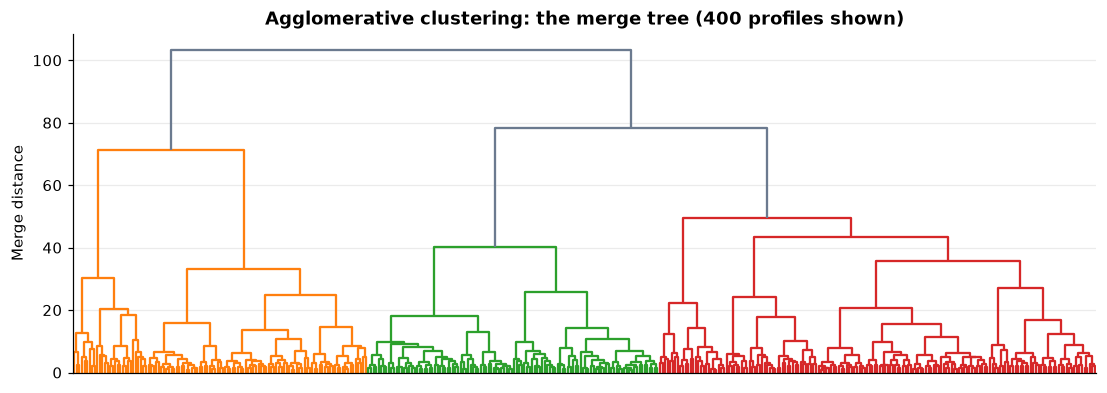

In [5]:
rng = np.random.default_rng(C.SEED)
sub = rng.choice(len(X), 400, replace=False)
fig, ax = plt.subplots(figsize=(12, 4))
dendrogram(linkage(X[sub], method="ward"), no_labels=True, color_threshold=None, ax=ax, above_threshold_color="#6b7a8f")
ax.set_ylabel("Merge distance"); ax.set_title("Agglomerative clustering: the merge tree (400 profiles shown)")
C.save(fig, "cluster_dendrogram")

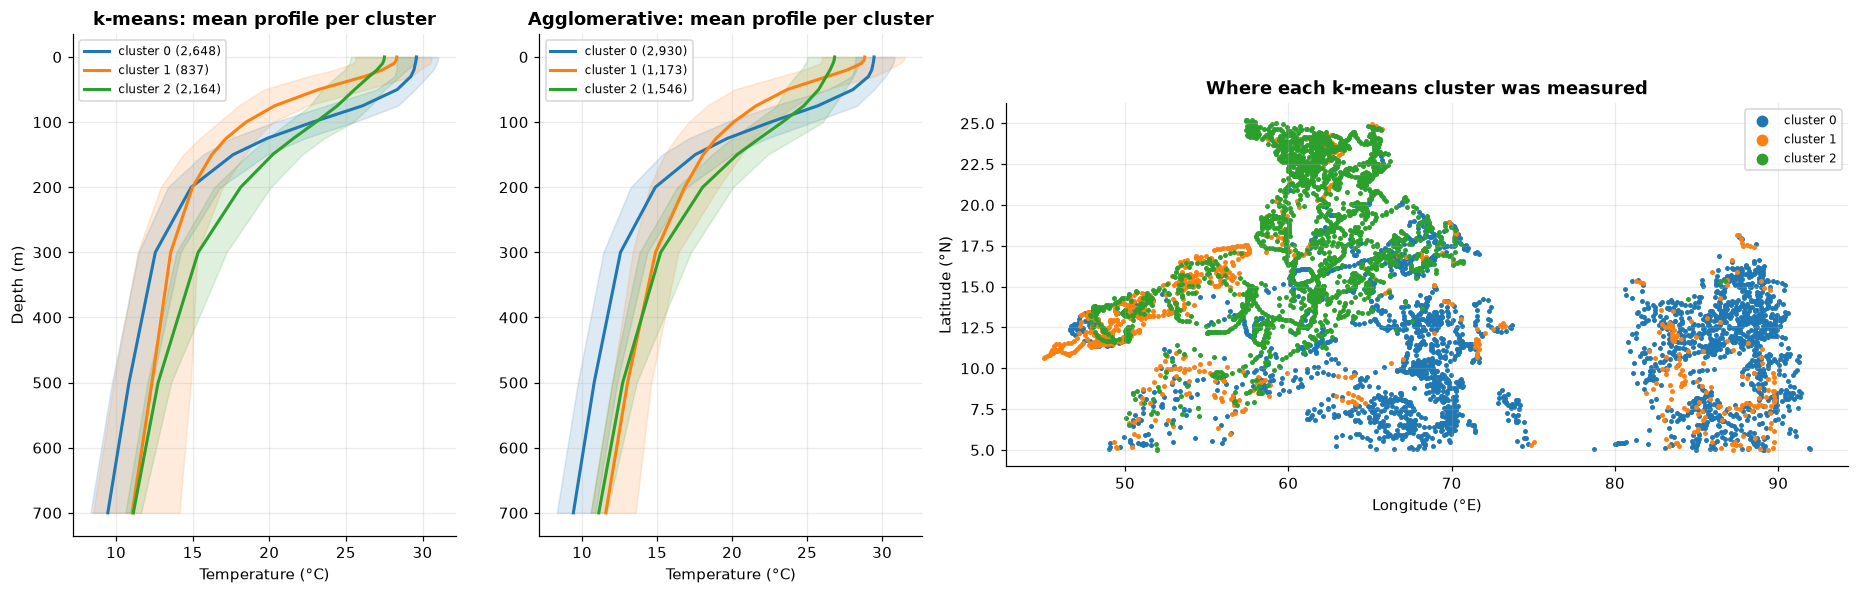

In [6]:
palette = sns.color_palette("tab10", K)
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1, 1, 2.2]})
for ax, m in zip(axes[:2], ["kmeans", "agglomerative"]):
    for c in range(K):
        p = X[meta[m].to_numpy() == c]
        ax.fill_betweenx(LEVELS, np.percentile(p, 10, axis=0), np.percentile(p, 90, axis=0), color=palette[c], alpha=0.15)
        ax.plot(p.mean(axis=0), LEVELS, color=palette[c], lw=2, label=f"cluster {c} ({len(p):,})")
    ax.invert_yaxis(); ax.set_xlabel("Temperature (°C)"); ax.set_title(f"{'k-means' if m == 'kmeans' else 'Agglomerative'}: mean profile per cluster")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Depth (m)")
for c in range(K):
    s = meta["kmeans"] == c
    axes[2].scatter(meta.loc[s, "lon"], meta.loc[s, "lat"], s=5, color=palette[c], label=f"cluster {c}")
axes[2].set_aspect("equal"); axes[2].set_xlabel("Longitude (°E)"); axes[2].set_ylabel("Latitude (°N)")
axes[2].set_title("Where each k-means cluster was measured"); axes[2].legend(markerscale=3, fontsize=8)
fig.tight_layout(); C.save(fig, "cluster_profiles_map")

## 5.4 Only now: do the clusters match the seas or the seasons?

The algorithm never saw a longitude or a date. If its clusters line up with the Bay of
Bengal and the Arabian Sea, it has rediscovered the geography from temperature alone.

                            ARI    NMI
basin                     0.096  0.191
season                    0.017  0.034
shuffled control (basin)  0.002  0.000
87% of Bay of Bengal floats fall into cluster 0; cluster 2 holds 51% of Arabian Sea floats but 0% of the Bay's.


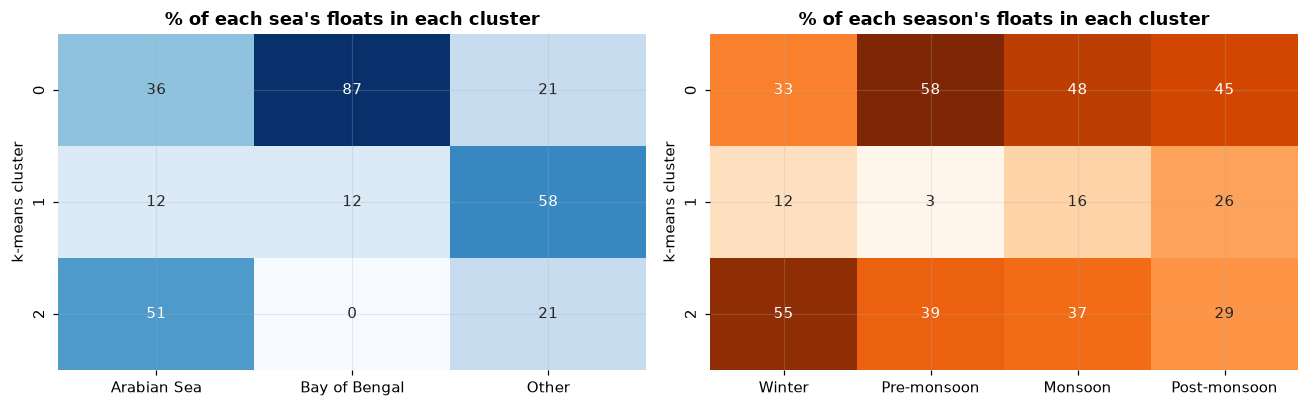

In [7]:
basin = meta["basin"].to_numpy()
two = basin != "Other"
match = {
    "basin": {"ARI": adjusted_rand_score(basin[two], meta["kmeans"][two]), "NMI": normalized_mutual_info_score(basin[two], meta["kmeans"][two])},
    "season": {"ARI": adjusted_rand_score(meta["season"], meta["kmeans"]), "NMI": normalized_mutual_info_score(meta["season"], meta["kmeans"])},
}
shuffled = rng.permutation(meta["kmeans"].to_numpy())
match["shuffled control (basin)"] = {"ARI": adjusted_rand_score(basin[two], shuffled[two]), "NMI": normalized_mutual_info_score(basin[two], shuffled[two])}
C.record("cluster.match", match)
by_basin = pd.crosstab(meta["kmeans"], meta["basin"], normalize="columns").mul(100).round(0)
by_season = pd.crosstab(meta["kmeans"], meta["season"], normalize="columns").mul(100).round(0)[["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]]
C.record("cluster.by_basin_pct", by_basin.to_dict()); C.record("cluster.by_season_pct", by_season.to_dict())
print(pd.DataFrame(match).T.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.heatmap(by_basin, annot=True, fmt=".0f", cmap="Blues", ax=axes[0], cbar=False); axes[0].set_title("% of each sea's floats in each cluster")
sns.heatmap(by_season, annot=True, fmt=".0f", cmap="Oranges", ax=axes[1], cbar=False); axes[1].set_title("% of each season's floats in each cluster")
for ax in axes:
    ax.set_ylabel("k-means cluster"); ax.set_xlabel("")
fig.tight_layout(); C.save(fig, "cluster_vs_labels")

bay, arab = by_basin["Bay of Bengal"], by_basin["Arabian Sea"]
print(f"{bay.max():.0f}% of Bay of Bengal floats fall into cluster {bay.idxmax()}; "
      f"cluster {bay.idxmin()} holds {arab[bay.idxmin()]:.0f}% of Arabian Sea floats but {bay.min():.0f}% of the Bay's.")

**Reading the result honestly.** Read the left table column by column. The clusters do
not split cleanly into "Bay" and "Arabian Sea", so the overall agreement (ARI) is
modest. But they are far from random: the Bay of Bengal is almost one water type, and
one type barely occurs in the Bay at all. Season explains even less. The water types
are a property of *place*, cutting across the two seas, and not of the calendar.